In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [2]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target)

print("Iris Dataset Loaded Successfully!")
print("Dataset Shape:", X.shape)
print("Total Features:", len(iris.feature_names))
print("Target Classes:", iris.target_names)

Iris Dataset Loaded Successfully!
Dataset Shape: (150, 4)
Total Features: 4
Target Classes: ['setosa' 'versicolor' 'virginica']


In [3]:
print("First 5 Rows:")
print(X.head())

First 5 Rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [4]:
print("Feature Names:")
print(X.columns.tolist())

Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [5]:
print("Flower Species:")
print(iris.target_names)

print("\nClass Distribution:")
print(y.value_counts().sort_index())

Flower Species:
['setosa' 'versicolor' 'virginica']

Class Distribution:
0    50
1    50
2    50
Name: count, dtype: int64


In [6]:
print("Missing Values:")
print(X.isnull().sum())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


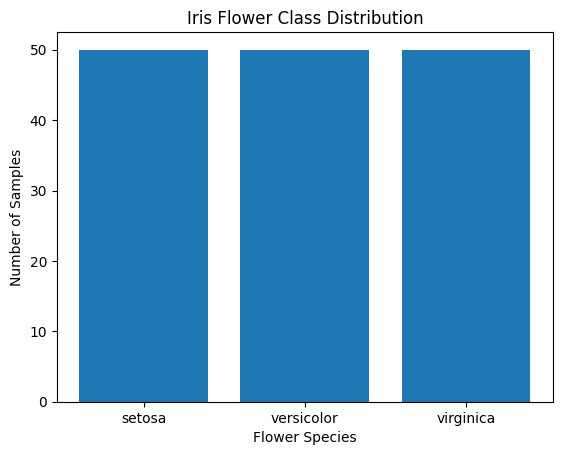

In [7]:
class_counts = y.value_counts().sort_index()

plt.bar(iris.target_names, class_counts)

plt.title("Iris Flower Class Distribution")
plt.xlabel("Flower Species")
plt.ylabel("Number of Samples")

plt.savefig("class_distribution.png")
plt.show()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 120
Testing Samples: 30


In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [10]:
lr_model = LogisticRegression(max_iter=200)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained!")

Logistic Regression Model Trained!


In [11]:
lr_predictions = lr_model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(lr_predictions[:10])

Actual Values:
[0 2 1 1 0 1 0 0 2 1]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1]


In [12]:
lr_accuracy = accuracy_score(y_test, lr_predictions)

lr_precision = precision_score(
    y_test, lr_predictions, average="weighted"
)

lr_recall = recall_score(
    y_test, lr_predictions, average="weighted"
)

lr_f1 = f1_score(
    y_test, lr_predictions, average="weighted"
)

print("Logistic Regression Evaluation")

print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1-Score:", lr_f1)

Logistic Regression Evaluation
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-Score: 0.9333333333333333


In [13]:
lr_cm = confusion_matrix(y_test, lr_predictions)

print(lr_cm)

[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


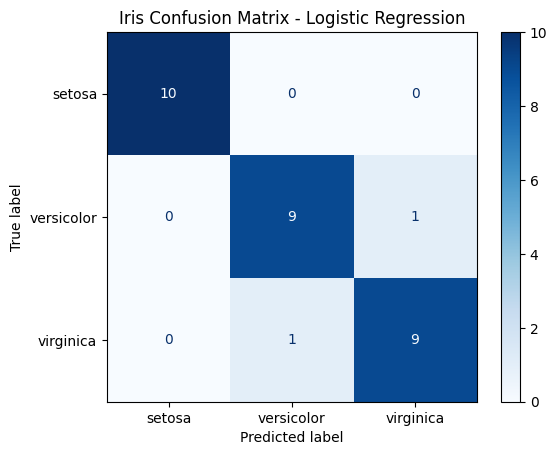

In [14]:
display = ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=iris.target_names
)

display.plot(cmap="Blues")

plt.title("Iris Confusion Matrix - Logistic Regression")
plt.savefig("confusion_matrix_logistic_regression.png")
plt.show()

In [15]:
print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=iris.target_names
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [16]:
for i in range(10):

    actual = iris.target_names[y_test.iloc[i]]
    predicted = iris.target_names[lr_predictions[i]]

    if actual == predicted:
        result = "Correct"
    else:
        result = "Wrong"

    print("Actual:", actual)
    print("Predicted:", predicted)
    print("Result:", result)
    print("--------------------")

Actual: setosa
Predicted: setosa
Result: Correct
--------------------
Actual: virginica
Predicted: virginica
Result: Correct
--------------------
Actual: versicolor
Predicted: versicolor
Result: Correct
--------------------
Actual: versicolor
Predicted: versicolor
Result: Correct
--------------------
Actual: setosa
Predicted: setosa
Result: Correct
--------------------
Actual: versicolor
Predicted: versicolor
Result: Correct
--------------------
Actual: setosa
Predicted: setosa
Result: Correct
--------------------
Actual: setosa
Predicted: setosa
Result: Correct
--------------------
Actual: virginica
Predicted: virginica
Result: Correct
--------------------
Actual: versicolor
Predicted: versicolor
Result: Correct
--------------------


In [17]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained!")

Decision Tree Model Trained!


In [18]:
dt_predictions = dt_model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("\nDecision Tree Predictions:")
print(dt_predictions[:10])

Actual Values:
[0 2 1 1 0 1 0 0 2 1]

Decision Tree Predictions:
[0 2 1 1 0 1 0 0 2 1]


In [19]:
dt_accuracy = accuracy_score(y_test, dt_predictions)

dt_precision = precision_score(
    y_test, dt_predictions, average="weighted"
)

dt_recall = recall_score(
    y_test, dt_predictions, average="weighted"
)

dt_f1 = f1_score(
    y_test, dt_predictions, average="weighted"
)

print("Decision Tree Evaluation")

print("Accuracy:", dt_accuracy)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1-Score:", dt_f1)

Decision Tree Evaluation
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-Score: 0.9333333333333333


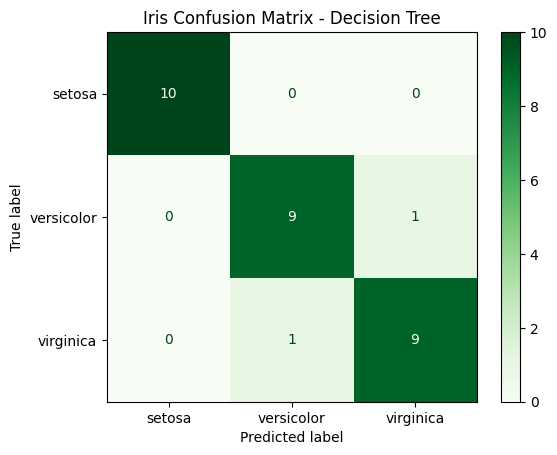

In [20]:
dt_cm = confusion_matrix(y_test, dt_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=dt_cm,
    display_labels=iris.target_names
)

display.plot(cmap="Greens")

plt.title("Iris Confusion Matrix - Decision Tree")
plt.savefig("confusion_matrix_decision_tree.png")
plt.show()

In [21]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],

    "Logistic Regression": [
        lr_accuracy,
        lr_precision,
        lr_recall,
        lr_f1
    ],

    "Decision Tree": [
        dt_accuracy,
        dt_precision,
        dt_recall,
        dt_f1
    ]
})

print(comparison)

      Metric  Logistic Regression  Decision Tree
0   Accuracy             0.933333       0.933333
1  Precision             0.933333       0.933333
2     Recall             0.933333       0.933333
3   F1-Score             0.933333       0.933333


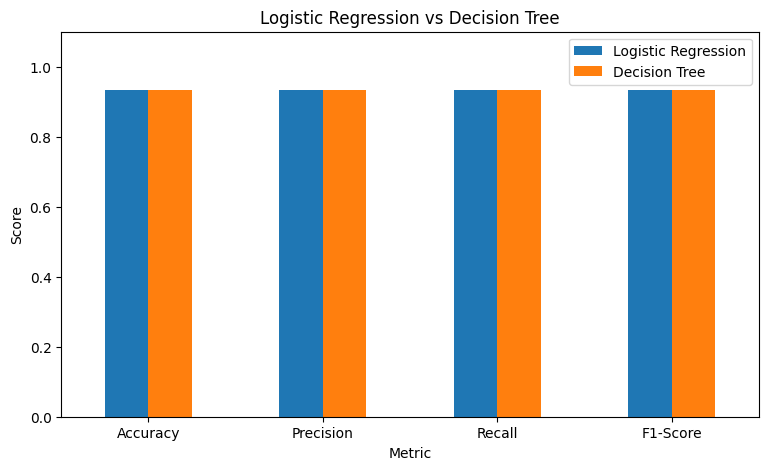

In [22]:
comparison.plot(
    x="Metric",
    kind="bar",
    figsize=(9, 5)
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)

plt.savefig("model_comparison.png")
plt.show()

In [23]:
if lr_accuracy > dt_accuracy:
    print("Logistic Regression performed better!")
elif dt_accuracy > lr_accuracy:
    print("Decision Tree performed better!")
else:
    print("Both models have the same accuracy!")

print("\nProject Completed Successfully!")

Both models have the same accuracy!

Project Completed Successfully!
